# 可选实验 - Softmax 函数
在本实验中，我们将探索 softmax 函数。在解决多类别分类问题时，这个函数既用于 Softmax 回归，也用于神经网络中。

<center>  <img  src="./images/C2_W2_Softmax_Header.PNG" width="600" />  <center/>

In [1]:
import numpy as np
import matplotlib.pyplot as plt
plt.style.use('./deeplearning.mplstyle')
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from IPython.display import display, Markdown, Latex
from sklearn.datasets import make_blobs
%matplotlib widget
from matplotlib.widgets import Slider
from lab_utils_common import dlc
from lab_utils_softmax import plt_softmax
import logging
logging.getLogger("tensorflow").setLevel(logging.ERROR)
tf.autograph.set_verbosity(0)

> **注意**：通常在本课程中，notebook 采用从 0 开始计数、到 N-1 结束的约定，即 $\sum_{i=0}^{N-1}$，而讲座则从 1 开始、到 N 结束，即 $\sum_{i=1}^{N}$。这是因为代码通常从 0 开始迭代，而在讲座中，从 1 数到 N 会得到更简洁、更精炼的方程。本 notebook 的方程比一般实验多，因此将打破这一约定，采用从 1 数到 N。

## Softmax 函数
在 softmax 回归以及带 Softmax 输出的神经网络中，都会生成 N 个输出，并选择其中一个输出作为预测的类别。在这两种情况下，都会由一个线性函数生成一个向量 $\mathbf{z}$，然后将其应用于 softmax 函数。softmax 函数把 $\mathbf{z}$ 转换成一个概率分布，如下所述。应用 softmax 之后，每个输出都介于 0 和 1 之间，且所有输出之和为 1，因此它们可以被解释为概率。较大的输入将对应较大的输出概率。<center>  <img  src="./images/C2_W2_SoftmaxReg_NN.png" width="600" />

softmax 函数可以写成：
$$a_j = \frac{e^{z_j}}{ \sum_{k=1}^{N}{e^{z_k} }} \tag{1}$$
输出 $\mathbf{a}$ 是一个长度为 N 的向量，所以对于 softmax 回归，你也可以写成：
$$\begin{align}
\mathbf{a}(x) =
\begin{bmatrix}
P(y = 1 | \mathbf{x}; \mathbf{w},b) \\
\vdots \\
P(y = N | \mathbf{x}; \mathbf{w},b)
\end{bmatrix}
=
\frac{1}{ \sum_{k=1}^{N}{e^{z_k} }}
\begin{bmatrix}
e^{z_1} \\
\vdots \\
e^{z_{N}} \\
\end{bmatrix} \tag{2}
\end{align}$$

这表明输出是一个概率向量。第一个条目是在给定输入 $\mathbf{x}$ 以及参数 $\mathbf{w}$ 和 $\mathbf{b}$ 的条件下，输入属于第一个类别的概率。
让我们创建一个 NumPy 实现：

In [2]:
def my_softmax(z):
    ez = np.exp(z)              #element-wise exponenial
    sm = ez/np.sum(ez)
    return(sm)

在下面，使用滑块改变 `z` 输入的值。

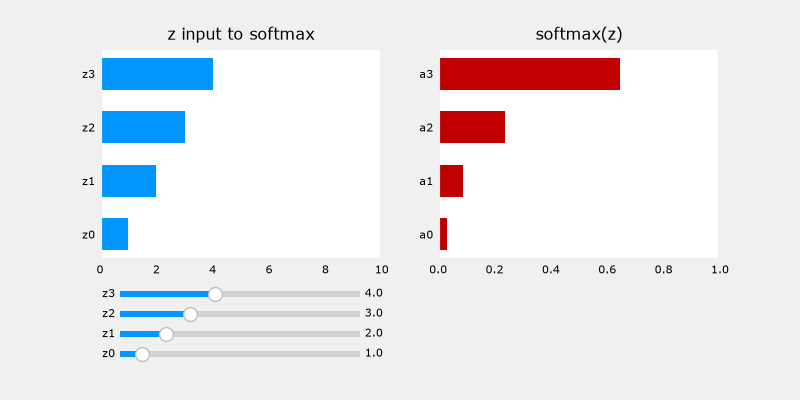

In [11]:
plt.close("all")
plt_softmax(my_softmax)

当你在上面改变各个 z 的值时，有几点值得注意：
* softmax 分子中的指数会放大数值上的微小差异
* 输出值之和为 1
* softmax 跨越所有输出。例如，`z0` 的改变会改变 `a0`-`a3` 的值。把这与其他激活函数（如 ReLU 或 Sigmoid，它们是单输入单输出）作对比。

## 代价
<center> <img  src="./images/C2_W2_SoftMaxCost.png" width="400" />    <center/>

与 Softmax 相关联的损失函数——交叉熵损失——为：
$$\begin{equation}
  L(\mathbf{a},y)=\begin{cases}
    -log(a_1), & \text{if $y=1$}.\\
        &\vdots\\
     -log(a_N), & \text{if $y=N$}
  \end{cases} \tag{3}
\end{equation}$$

其中 y 是这个样本的目标类别，$\mathbf{a}$ 是 softmax 函数的输出。特别地，$\mathbf{a}$ 中的值是概率，其和为 1。
>**回顾：** 在本课程中，Loss（损失）针对单个样本，而 Cost（代价）涵盖所有样本。


请注意，在上面的 (3) 中，只有与目标对应的那一行对损失有贡献，其他行为零。要写出代价方程，我们需要一个"指示函数"（indicator function），当索引与目标匹配时它为 1，否则为 0。
    $$\mathbf{1}\{y == n\} = =\begin{cases}
    1, & \text{if $y==n$}.\\
    0, & \text{otherwise}.
  \end{cases}$$
现在代价为：
$$\begin{align}
J(\mathbf{w},b) = -\frac{1}{m} \left[ \sum_{i=1}^{m} \sum_{j=1}^{N}  1\left\{y^{(i)} == j\right\} \log \frac{e^{z^{(i)}_j}}{\sum_{k=1}^N e^{z^{(i)}_k} }\right] 
\tag{4}
\end{align}$$

其中 $m$ 是样本数量，$N$ 是输出数量。这是所有损失的平均值。

## Tensorflow
本实验将讨论在 Tensorflow 中实现 softmax 交叉熵损失的两种方式："显而易见"的方法和"更受推荐"的方法。前者最为直接，而后者在数值上更稳定。

让我们先创建一个数据集来训练一个多类别分类模型。

In [ ]:
# make  dataset for example
centers = [[-5, 2], [-2, -2], [1, 2], [5, -2]]
X_train, y_train = make_blobs(n_samples=2000, centers=centers, cluster_std=1.0, random_state=30)

### *显而易见*的组织方式

下面的模型把 softmax 作为最后一个 Dense 层中的激活来实现。
损失函数则在 `compile` 指令中单独指定。

损失函数是 `SparseCategoricalCrossentropy`。这个损失在上面的 (3) 中描述。在这个模型中，softmax 发生在最后一层。损失函数接受 softmax 的输出，即一个概率向量。

In [ ]:
model = Sequential(
    [
        Dense(25, activation = 'relu'),
        Dense(15, activation = 'relu'),
        Dense(4, activation = 'softmax')    # < softmax activation here
    ]
)
model.compile(
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    optimizer=tf.keras.optimizers.Adam(0.001),
)

model.fit(
    X_train,y_train,
    epochs=10
)
        

Epoch 1/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 846us/step - loss: 0.8280 
Epoch 2/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 761us/step - loss: 0.3315
Epoch 3/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 774us/step - loss: 0.1530
Epoch 4/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 762us/step - loss: 0.0915
Epoch 5/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 758us/step - loss: 0.0676
Epoch 6/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 744us/step - loss: 0.0559
Epoch 7/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 758us/step - loss: 0.0488
Epoch 8/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 750us/step - loss: 0.0440
Epoch 9/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 742us/step - loss: 0.0401
Epoch 10/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 655us/step - loss: 0.0372


因为 softmax 被集成到输出层中，所以输出是一个概率向量。

In [6]:
p_nonpreferred = model.predict(X_train)
print(p_nonpreferred [:2])
print("largest value", np.max(p_nonpreferred), "smallest value", np.min(p_nonpreferred))

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 873us/step
[[3.97e-03 4.54e-03 9.81e-01 1.02e-02]
 [9.96e-01 3.32e-03 6.87e-05 7.94e-04]]
largest value 1.0 smallest value 6.4278782e-09


### 更受推荐的方式 <img align="Right" src="./images/C2_W2_softmax_accurate.png"  style=" width:400px; padding: 10px 20px ; ">
回顾讲座，如果在训练期间把 softmax 和损失结合起来，可以得到更稳定、更准确的结果。这里展示的"更受推荐"的组织方式就实现了这一点。

在更受推荐的组织方式中，最后一层使用线性激活。由于历史原因，这种形式的输出被称为 *logits*。损失函数有一个额外的参数：`from_logits = True`。这告知损失函数应把 softmax 运算包含在损失计算中。这样就可以采用一种优化过的实现。

In [7]:
preferred_model = Sequential(
    [ 
        Dense(25, activation = 'relu'),
        Dense(15, activation = 'relu'),
        Dense(4, activation = 'linear')   #<-- Note
    ]
)
preferred_model.compile(
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),  #<-- Note
    optimizer=tf.keras.optimizers.Adam(0.001),
)

preferred_model.fit(
    X_train,y_train,
    epochs=10
)
        

Epoch 1/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 751us/step - loss: 1.1282 
Epoch 2/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 770us/step - loss: 0.5113
Epoch 3/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 765us/step - loss: 0.2089
Epoch 4/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 662us/step - loss: 0.1141
Epoch 5/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 664us/step - loss: 0.0807
Epoch 6/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 747us/step - loss: 0.0633
Epoch 7/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 743us/step - loss: 0.0543
Epoch 8/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 622us/step - loss: 0.0483
Epoch 9/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 655us/step - loss: 0.0441
Epoch 10/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 758us/step - loss: 0.0408


#### 输出处理
请注意，在更受推荐的模型中，输出不是概率，而是可以从很大的负数到很大的正数。当执行一个期望得到概率的预测时，必须把输出经过一个 softmax。
让我们看看更受推荐模型的输出：

In [8]:
p_preferred = preferred_model.predict(X_train)
print(f"two example output vectors:\n {p_preferred[:2]}")
print("largest value", np.max(p_preferred), "smallest value", np.min(p_preferred))

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 839us/step
two example output vectors:
 [[-1.77 -2.15  3.7  -0.26]
 [ 8.12  2.94 -2.26 -6.91]]
largest value 13.624815 smallest value -10.338811


输出的预测值不是概率！
如果想要的输出是概率，就应当用一个 [softmax](https://www.tensorflow.org/api_docs/python/tf/nn/softmax) 来处理输出。

In [9]:
sm_preferred = tf.nn.softmax(p_preferred).numpy()
print(f"two example output vectors:\n {sm_preferred[:2]}")
print("largest value", np.max(sm_preferred), "smallest value", np.min(sm_preferred))

two example output vectors:
 [[4.09e-03 2.79e-03 9.75e-01 1.86e-02]
 [9.94e-01 5.58e-03 3.10e-05 2.96e-07]]
largest value 0.99999917 smallest value 4.0945514e-11


要选择最可能的类别，并不需要 softmax。可以使用 [np.argmax()](https://numpy.org/doc/stable/reference/generated/numpy.argmax.html) 找到最大输出的索引。

In [10]:
for i in range(5):
    print( f"{p_preferred[i]}, category: {np.argmax(p_preferred[i])}")

[-1.77 -2.15  3.7  -0.26], category: 2
[ 8.12  2.94 -2.26 -6.91], category: 0
[ 6.04  2.71 -1.73 -5.33], category: 0
[ 0.39  5.16 -2.17 -1.66], category: 1
[ 0.68 -5.8   6.16 -3.18], category: 2


## SparseCategorialCrossentropy 还是 CategoricalCrossEntropy
Tensorflow 对目标值有两种可能的格式，损失的选择决定了期望哪一种。
- SparseCategorialCrossentropy：期望目标是一个与索引对应的整数。例如，如果有 10 个可能的目标值，y 将介于 0 和 9 之间。
- CategoricalCrossEntropy：期望样本的目标值采用独热（one-hot）编码，即目标索引处的值为 1，其余 N-1 个条目为零。一个有 10 个可能目标值、目标为 2 的样本将是 [0,0,1,0,0,0,0,0,0,0]。

## 恭喜完成！
在本实验中，你
- 更加熟悉了 softmax 函数及其在 softmax 回归和神经网络 softmax 激活中的使用。
- 学会了 Tensorflow 中更受推荐的模型构建方式：
    - 最后一层不使用激活（等同于线性激活）
    - SparseCategoricalCrossentropy 损失函数
    - 使用 from_logits=True
- 认识到与 ReLU 和 Sigmoid 不同，softmax 跨越多个输出。